# Day 1 — Try it yourself: a model that recognises pictures

LearnForge · AI/ML Learning Journey · Day 1, section 3

Photo apps, medical imaging and self-driving cars all use **image classification**: a model looks at the pixels of a picture and predicts what it shows. Here you train a small one on handwritten digits (0–9).

Run each cell in order with **Shift + Enter**. Everything runs in a few seconds; nothing is downloaded.

## 1. Look at the pictures

Each picture is 8 × 8 pixels, stored as 64 numbers from 0 (white) to 16 (black).

(1797, 8, 8)


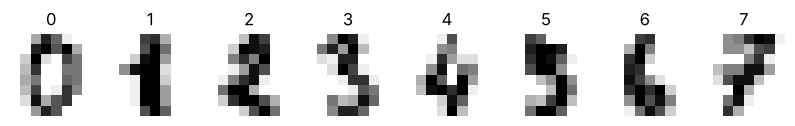

In [1]:
from sklearn.datasets import load_digits
import matplotlib.pyplot as plt

digits = load_digits()
print(digits.images.shape)   # (number of pictures, 8, 8)

fig, axes = plt.subplots(1, 8, figsize=(10, 2))
for ax, image, label in zip(axes, digits.images, digits.target):
    ax.imshow(image, cmap="gray_r")
    ax.set_title(label)
    ax.axis("off")
plt.show()

## 2. Keep some pictures aside for testing

A fair test uses pictures the model has **not** seen while learning.

In [2]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    digits.data, digits.target, test_size=0.25, random_state=0)
print(len(X_train), "pictures to learn from,", len(X_test), "to test on")

1347 pictures to learn from, 450 to test on


## 3. Train the model

`fit()` learns which pixel patterns belong to which digit.

In [3]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=2000)
model.fit(X_train, y_train)
print("accuracy on unseen pictures:", round(model.score(X_test, y_test) * 100, 1), "%")

accuracy on unseen pictures: 95.3 %


## 4. See its predictions

Red titles are mistakes. Even a good model gets some pictures wrong.

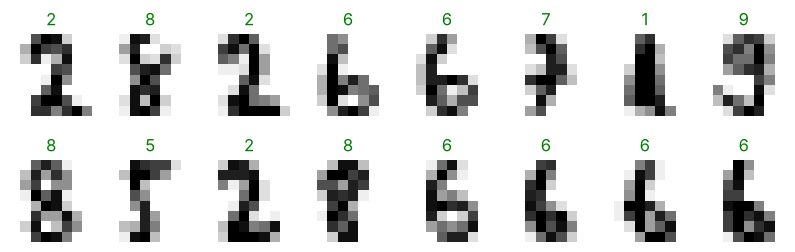

21 of 450 test pictures were misread


In [4]:
predictions = model.predict(X_test)

fig, axes = plt.subplots(2, 8, figsize=(10, 3))
for ax, image, guess, truth in zip(axes.ravel(), X_test, predictions, y_test):
    ax.imshow(image.reshape(8, 8), cmap="gray_r")
    ax.set_title(f"{guess}", color="green" if guess == truth else "red")
    ax.axis("off")
plt.show()

wrong = (predictions != y_test).sum()
print(wrong, "of", len(y_test), "test pictures were misread")

## 5. Think about it

- Which digits does the model confuse? Why might a 3 look like an 8?
- Real photo apps use **deep learning** on much larger pictures, but the idea is the same: learn from labelled examples, then predict labels for new pictures.